EECE5644 HW 1 Question 5

(a) Download two-gaussians.py from Canvas. Run the code and describe, in one or two paragraphs,
what it does.

    >This code generates two 'frozen' multivariate gaussian objects using scipy's multivariate_normal() function, one for salmon and the other sea bass with different mean and covariance matrices (rv_pos and rv_neg). Arrays x_pos and x_neg are filled with 1000 random samples according to a binomial distribution for sea bass and salmon gaussian onjects. It then sstimates the mean, covariance, and prior for each Gaussian from samples for each distribution. It joins samples to create a classification dataset and runs the Naive_classifer over the sampels to generate predictions. It calls metrics to calculate the TPR and FPR, then plots the associated Recevier Operator Characteristic (ROC) curve.


(b) Implement two different classifiers under the assumption that the conditional distributions p(x | ωi) are:
• Gaussian with different means and covariance equal to the identity (i.e. Σi = I).
• Gaussian with different means but a common covariance Σ.

    >See code below that generates pooled_covariance() and make_common_cov_discriminants()

(c) What shape does the decision/separating surface have for these two classifiers?

    >The two classifiers are linear discriminant functions, therefore their seperating surface is a hyperplane.

(d) Add the ROC curves for these two classifiers to the ROC plot included in the file given to you. Include
the final plot in your report.
    >See code below and the associated ROC curves

Eigenvalues of cov_pos are: [1.8+0.j 0.2+0.j]
Eigenvalues of cov_neg are: [0.18993827+0.j 1.81006173+0.j]
rv_pos = <scipy.stats._multivariate.multivariate_normal_frozen object at 0x000001F63FC997F0>
rv_neg = <scipy.stats._multivariate.multivariate_normal_frozen object at 0x000001F63FC98050>
Positive class estimates: [0.98235749 3.00963093] [[0.92238131 0.7448302 ]
 [0.7448302  0.95946378]] 0.487
Negative class estimates: [3.9230447  3.96557996] [[0.94097836 0.72525226]
 [0.72525226 0.91901655]] 0.513
Scanning tau for naive...
FPR = 0.0 TPR = 0.0
FPR = 0.11695906432748537 TPR = 0.10061601642710473
FPR = 0.1949317738791423 TPR = 0.19917864476386038
FPR = 0.30214424951267055 TPR = 0.3141683778234086
FPR = 0.3996101364522417 TPR = 0.42505133470225875
FPR = 0.5282651072124757 TPR = 0.5174537987679672
FPR = 0.6081871345029239 TPR = 0.648870636550308
FPR = 0.6978557504873294 TPR = 0.704312114989733
FPR = 0.7914230019493177 TPR = 0.7864476386036962
FPR = 0.8966861598440545 TPR = 0.882956878850

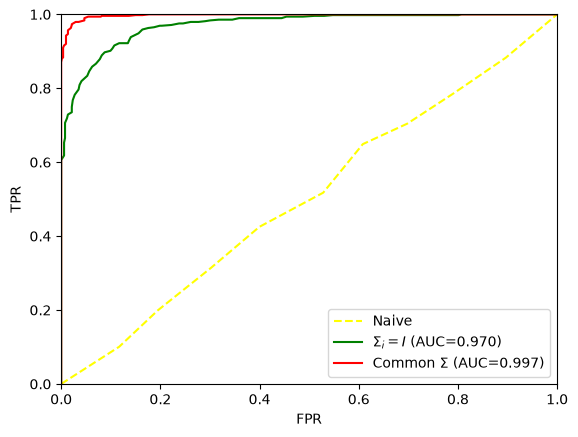

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from numpy.linalg import eigvals
# See https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multivariate_normal.html



# Set random seed for reproducibility
np.random.seed(42)



def get_mean_and_covariance(X):
    """ Get the mean  mu in IR^d and covariance Sigma in IR^{d times d} from samples in matrix X in IR^{n x d}. Each row corresponds to a different sample"""
    e_mean = np.mean(X,0)
    e_cov = np.cov(X,rowvar = False)
    return (e_mean,e_cov)



def tau_range(X,g_pos,g_neg):
    """return the range of taus that one needs to span to create the ROC curve with these discriminant functions"""
    n,d = X.shape
    scores = [g_pos(X[i,:])-g_neg(X[i,:]) for i in range(n)]
    return min(scores),max(scores)
   

def predict(X,g_pos,g_neg,tau):
    """Generate predictions (+1/-1) over samples in X using discriminant functions g_pos, g_neg with threshold tau"""
    y_pred = []
    n,d = X.shape
    for i in range(n):
        x = X[i,:]
        y_pred.append(np.sign(g_pos(x)-g_neg(x)-tau))
    return y_pred     
    


def metrics(y_pred,y_true):
    """ Output the FPR and the TPR. These are defined in terms of the following quantities:
      
                 P = # entries y_true in that are  + 1
                 N = # entries y_true in that are  - 1
 
                 
                 TP = # entries for which  y_pred=+1 and y_true=+1  
                 FP = # entries for which  y_pred=-1 but y_true = +1  
                 TN = # entries for which y_pred=-1 and y_true = -1  
                 FN =  # entries for which y_pred=-1 but y_true = +1  


                 TPR = TP / P
                 FPR = FP / N
        Inputs are:
             - y_pred: predictions
             - y_true: ground truth values

        The return value is a tuple containing
             - #P,#N,#TP,#FP,#TN,#FN
    """

    pairs = [  (int(x),int(y))  for (x,y) in zip(y_pred,y_true)]
    new_pairs = [ (pred_label,pred_label*true_label)  for (pred_label,true_label) in pairs ]        
    

    TP = 1.*new_pairs.count( (1,1) )
    FP = 1.*new_pairs.count( (1,-1) )
    TN = 1.*new_pairs.count( (-1,1) )
    FN = 1.*new_pairs.count( (-1,-1) )
    P = TP+FN
    N = TN+FP

    TPR = 1.*TP/P
    FPR = 1.*FP/N
    return FPR,TPR

###################################################################
###
### The following code was generated by Claude Sonnet 5.5 (Anthropic)
###
###################################################################


def make_identity_cov_discriminants(mean_pos, mean_neg, prior_pos, prior_neg):
    """
    Case 1: p(x | w_i) = N(mu_i, I), i.e. Sigma_i = I for both classes.

    With Sigma = I the log-likelihood reduces (up to a common constant) to
    the negative squared Euclidean distance to the class mean:

        g_i(x) = -1/2 * ||x - mu_i||^2 + ln P(w_i)

    This is a minimum-distance-to-mean classifier with a prior correction.
    The decision boundary is a hyperplane orthogonal to (mu_pos - mu_neg).

    Inputs:
        mean_pos, mean_neg   : class means, shape (d,)
        prior_pos, prior_neg : class priors P(w_+), P(w_-)
    Returns:
        (g_pos, g_neg): functions mapping a single sample x in IR^d to a float.
    """
    mu_p = np.asarray(mean_pos, dtype=float)
    mu_n = np.asarray(mean_neg, dtype=float)

    def g_pos(x):
        diff = x - mu_p
        return -0.5 * diff @ diff + np.log(prior_pos)

    def g_neg(x):
        diff = x - mu_n
        return -0.5 * diff @ diff + np.log(prior_neg)

    return g_pos, g_neg


def pooled_covariance(cov_pos, cov_neg, n_pos, n_neg):
    """
    Pooled (common) covariance estimate from the two class covariances:

        Sigma = ((n_+ - 1) S_+ + (n_- - 1) S_-) / (n_+ + n_- - 2)

    This is the unbiased estimate of a shared covariance matrix.
    """
    return ((n_pos - 1) * cov_pos + (n_neg - 1) * cov_neg) / (n_pos + n_neg - 2)


def make_common_cov_discriminants(mean_pos, mean_neg, cov, prior_pos, prior_neg):
    """
    Case 2: p(x | w_i) = N(mu_i, Sigma) with a covariance Sigma shared by
    both classes (this is Linear Discriminant Analysis).

    Dropping the terms that are the same for both classes:

        g_i(x) = -1/2 (x - mu_i)^T Sigma^{-1} (x - mu_i) + ln P(w_i)

    This is the squared Mahalanobis distance to the class mean, plus a prior
    correction. The quadratic term x^T Sigma^{-1} x cancels in g_pos - g_neg,
    so the decision boundary is still a hyperplane, now tilted by Sigma^{-1}.

    Inputs:
        mean_pos, mean_neg   : class means, shape (d,)
        cov                  : common covariance Sigma, shape (d, d)
        prior_pos, prior_neg : class priors
    Returns:
        (g_pos, g_neg): functions mapping a single sample x in IR^d to a float.
    """
    mu_p = np.asarray(mean_pos, dtype=float)
    mu_n = np.asarray(mean_neg, dtype=float)
    cov = np.asarray(cov, dtype=float)

    def mahalanobis_sq(x, mu):
        diff = x - mu
        # solve(Sigma, diff) is more stable than forming Sigma^{-1} explicitly
        return diff @ np.linalg.solve(cov, diff)

    def g_pos(x):
        return -0.5 * mahalanobis_sq(x, mu_p) + np.log(prior_pos)

    def g_neg(x):
        return -0.5 * mahalanobis_sq(x, mu_n) + np.log(prior_neg)

    return g_pos, g_neg


def roc_curve(X, y, g_pos, g_neg, num_taus=200):
    """
    Sweep the threshold tau over the range of scores g_pos - g_neg and return
    the ROC curve for the resulting classifier.

    Scores are computed once and reused for every tau. tau is swept slightly
    beyond [min score, max score] so the curve reaches both (0,0) and (1,1)
    (at exactly tau = min or max, np.sign would return 0 for that sample).

    Returns:
        FPR_list, TPR_list : lists of floats, ordered by increasing tau
        auc                : area under the ROC curve (trapezoid rule)
    """
    lo, hi = tau_range(X, g_pos, g_neg)
    pad = 1e-6 * max(1.0, hi - lo)
    taus = np.linspace(lo - pad, hi + pad, num_taus)

    scores = np.array([g_pos(x) - g_neg(x) for x in X])

    FPRs, TPRs = [], []
    for tau in taus:
        y_pred = np.where(scores - tau > 0, 1, -1)
        FPR, TPR = metrics(y_pred, y)
        FPRs.append(FPR)
        TPRs.append(TPR)

    # FPR decreases as tau increases; reverse so x is ascending for the AUC
    fx, ty = np.array(FPRs[::-1]), np.array(TPRs[::-1])
    auc = float(np.sum(0.5 * (ty[1:] + ty[:-1]) * np.diff(fx)))
    return FPRs, TPRs, auc


####################################################
####
#### end code generated by Claude Sonnet 5.5 (Anthropic)
####
####################################################

def naive_classifier(q,n):
    return -np.sign(np.random.rand(n)-q)


p = 0.5 # prior probability of positive class
n = 1000 # total number of samples


if __name__=="__main__":
    # Generate two multivariate Gaussian random variable objects
    mean_pos, cov_pos = [1, 3], [[1, 0.8], [0.8, 1]]
    e=eigvals(cov_pos)
    print("Eigenvalues of cov_pos are:",e)
    rv_pos = multivariate_normal(mean_pos, cov_pos)

    mean_neg, cov_neg = [4, 4], [[0.99, 0.81], [0.81, 1.01]]
    e=eigvals(cov_neg)
    print("Eigenvalues of cov_neg are:",e)
    rv_neg = multivariate_normal(mean_neg, cov_neg)


    prior_pos = p
    prior_neg = 1-p

    # Generate samples
    n_pos = np.random.binomial(n,p)
    n_neg = n - n_pos
    X_pos = rv_pos.rvs(size = n_pos)
    X_neg = rv_neg.rvs(size = n_neg)


    # Create a scatter plot for the samples
 #   fig	 = plt.figure()
 #   ax = fig.add_subplot(111)
 #   ax.scatter(X_pos[:, 0], X_pos[:, 1], label='Sea Bass (+)', alpha=0.7,c="blue")
 #   ax.scatter(X_neg[:, 0], X_neg[:, 1], label='Salmon (-)', alpha=0.7, c="orange")

    # Add contours of the pdfs
 #   x1, x2 = np.mgrid[-1:8:.01, -1:6:.01]
 #   positions = np.dstack((x1, x2))
 #   ax.contour(x1, x2, rv_pos.pdf(positions),levels=5,colors="blue")
 #   ax.contour(x1, x2, rv_neg.pdf(positions), levels=5, colors="orange")


 #   ax.set_xlabel('$x_1$')
 #   ax.set_ylabel('$x_2$')
 #   ax.legend()


    #plt.savefig("two-gaussians.pdf", format="pdf", bbox_inches="tight")

   
    # Estimate the mean, covariance, and prior for each Gaussian from samples
    e_mean_pos, e_cov_pos = get_mean_and_covariance(X_pos)
    e_mean_neg, e_cov_neg = get_mean_and_covariance(X_neg)
    e_prior_pos = 1. * n_pos / n
    e_prior_neg = 1. * n_neg / n

    print ("Positive class estimates:", e_mean_pos,e_cov_pos,e_prior_pos)
    print ("Negative class estimates:", e_mean_neg,e_cov_neg,e_prior_neg)


    # Join samples to create a classification dataset
    X = np.concatenate((X_pos,X_neg))
    y = np.concatenate( (np.ones(n_pos),-np.ones(n_neg)) )
 
    
    #create ROC Curve for naive classifier


    FPR_naive_list=[]
    TPR_naive_list=[]
    delta = (1.0-0.0)/10
    print('Scanning tau for naive...')
    for q in np.arange(0.,1+delta,delta):
        #generate predictions
        y_pred = naive_classifier(q,n)

        #compute FPR and TPR
        FPR,TPR = metrics(y_pred,y)
        print('FPR =',FPR,'TPR =',TPR)
        FPR_naive_list.append(FPR)
        TPR_naive_list.append(TPR)
    print('...done with',len(FPR_naive_list),'measurements')
    
    # Plot the ROC curve
    fig	 = plt.figure()
    ax = fig.add_subplot(111)
    ax.plot(FPR_naive_list, TPR_naive_list, linestyle='dashed' ,color='yellow',label = 'Naive')



    ####################################################
    ####
    #### The following code was generated by Claude Sonnet 5.5 (Anthropic)
    ####
    ####################################################

    # Classifier 1: Sigma_i = I  (only the means and priors are used)
    g_pos_I, g_neg_I = make_identity_cov_discriminants(
        e_mean_pos, e_mean_neg, e_prior_pos, e_prior_neg)

    # Classifier 2: common covariance Sigma (pooled estimate)
    e_cov_common = pooled_covariance(e_cov_pos, e_cov_neg, n_pos, n_neg)
    print("Pooled covariance estimate:\n", e_cov_common)
    g_pos_S, g_neg_S = make_common_cov_discriminants(
        e_mean_pos, e_mean_neg, e_cov_common, e_prior_pos, e_prior_neg)

    FPR_I, TPR_I, auc_I = roc_curve(X, y, g_pos_I, g_neg_I)
    FPR_S, TPR_S, auc_S = roc_curve(X, y, g_pos_S, g_neg_S)


    # Plot the ROC curves
    #fig = plt.figure()
    #ax = fig.add_subplot(111)
    ax.plot(FPR_I, TPR_I, color='green', label=r'$\Sigma_i = I$ (AUC=%.3f)' % auc_I)
    ax.plot(FPR_S, TPR_S, color='red', label=r'Common $\Sigma$ (AUC=%.3f)' % auc_S)


    ####################################################
    ####
    #### end code generated by Claude Sonnet 5.5 (Anthropic)
    ####
    ####################################################

    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.set(xlim=(0.0, 1.0), ylim=(0.0, 1.0))
    ax.legend(loc='lower right')

    plt.savefig("ROC.pdf", format="pdf", bbox_inches="tight")
    
    
